# Model 2 · 3. Training dan memilih model

Empat model machine learning klasik dilatih dengan data **train**, lalu dibandingkan dengan **val**.
Model terbaik di val dipilih. Soal ujian **tidak dilihat** di notebook ini, supaya pemilihan model jujur.

| Model | Pengaturan |
|---|---|
| Random Forest | 300 pohon, `max_features='log2'` |
| Extra Trees | 500 pohon, `max_features='sqrt'` |
| HistGradientBoosting | `learning_rate=0.05`, `max_iter=500` |
| Gabungan (soft voting) | rata-rata peluang dari ketiganya |

Semua memakai `random_state=0` supaya hasilnya bisa diulang. Butuh sekitar 5 menit.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import dump
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

KELAS = ['Blackheads', 'Cyst', 'Papules', 'Pustules', 'Whiteheads']
SIMPAN = ROOT / 'hasil' / 'model2'
SEED = 0

z = np.load(SIMPAN / 'ciri_warna_titik.npz')   # dibuat oleh notebook 2
X = {k: z[k] for k in ('latih', 'val')}
Y = {k: z['y_' + k] for k in ('latih', 'val')}
print({k: X[k].shape for k in X})
print('jumlah train per jenis:', dict(zip(KELAS, np.bincount(Y['latih']))))

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


{'latih': (8618, 60), 'val': (802, 60)}
jumlah train per jenis: {'Blackheads': np.int64(1971), 'Cyst': np.int64(1130), 'Papules': np.int64(1845), 'Pustules': np.int64(1851), 'Whiteheads': np.int64(1821)}


In [2]:
def buat(nama, seed=SEED):
    rf = RandomForestClassifier(300, max_features='log2', n_jobs=-1, random_state=seed)
    et = ExtraTreesClassifier(500, max_features='sqrt', n_jobs=-1, random_state=seed)
    hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, random_state=seed)
    return {'Random Forest': rf, 'Extra Trees': et, 'Gradient Boosting': hgb,
            'Gabungan RF+ET+HGB': VotingClassifier([('rf', rf), ('et', et), ('hgb', hgb)], voting='soft')}[nama]


PILIHAN = ['Random Forest', 'Extra Trees', 'Gradient Boosting', 'Gabungan RF+ET+HGB']
hasil_val, model_val = [], {}
for nama in PILIHAN:
    t0 = time.time()
    m = buat(nama).fit(X['latih'], Y['latih'])
    p = m.predict(X['val'])
    model_val[nama] = m
    hasil_val.append({'model': nama, 'val_akurasi': accuracy_score(Y['val'], p),
                      'val_macro_F1': f1_score(Y['val'], p, average='macro'), 'detik': round(time.time() - t0)})
    print(hasil_val[-1], flush=True)
hasil_val = pd.DataFrame(hasil_val).round(3)
hasil_val.to_csv(SIMPAN / 'pilih_model_val.csv', index=False)
print()
print(hasil_val.to_string(index=False))

{'model': 'Random Forest', 'val_akurasi': 0.7082294264339152, 'val_macro_F1': 0.6795715801565169, 'detik': 2}


{'model': 'Extra Trees', 'val_akurasi': 0.7331670822942643, 'val_macro_F1': 0.6986066313853083, 'detik': 2}


{'model': 'Gradient Boosting', 'val_akurasi': 0.7443890274314214, 'val_macro_F1': 0.7260378750787172, 'detik': 23}


{'model': 'Gabungan RF+ET+HGB', 'val_akurasi': 0.7456359102244389, 'val_macro_F1': 0.7267950423645594, 'detik': 44}



             model  val_akurasi  val_macro_F1  detik
     Random Forest        0.708         0.680      2
       Extra Trees        0.733         0.699      2
 Gradient Boosting        0.744         0.726     23
Gabungan RF+ET+HGB        0.746         0.727     44


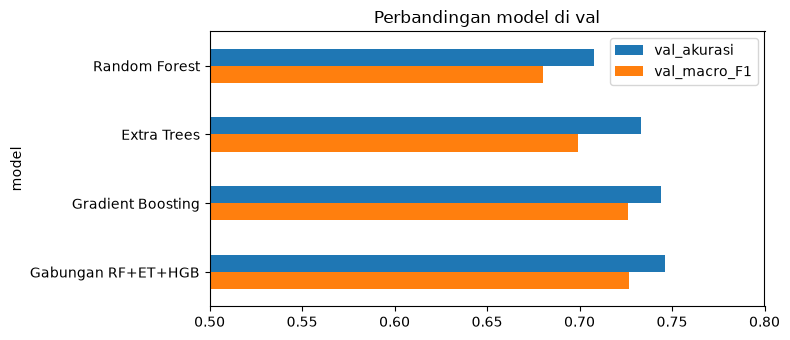

Model terpilih (macro F1 val tertinggi): Gabungan RF+ET+HGB


In [3]:
ax = hasil_val.set_index('model')[['val_akurasi', 'val_macro_F1']].plot.barh(figsize=(8, 3.5), xlim=(0.5, 0.8))
ax.set_title('Perbandingan model di val'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

TERPILIH = hasil_val.sort_values('val_macro_F1', ascending=False).iloc[0]['model']
print('Model terpilih (macro F1 val tertinggi):', TERPILIH)

## F1 tiap jenis di val (model terpilih)

In [4]:
model = model_val[TERPILIH]
print(classification_report(Y['val'], model.predict(X['val']), target_names=KELAS, digits=3))

              precision    recall  f1-score   support

  Blackheads      0.890     0.853     0.871       170
        Cyst      0.686     0.500     0.579        70
     Papules      0.672     0.748     0.708       222
    Pustules      0.693     0.681     0.687       166
  Whiteheads      0.781     0.799     0.790       174

    accuracy                          0.746       802
   macro avg      0.744     0.716     0.727       802
weighted avg      0.747     0.746     0.745       802



## Simpan model
Disimpan ke `hasil/model2/`. File di `models/` (yang dipakai aplikasi) **tidak ditimpa**; isinya model yang sama
hasil notebook ini (sudah dicek: akurasi ujian sama, 0,735).

In [5]:
from ciri_jerawat import UKURAN

berkas = SIMPAN / 'model2_gabungan_warna_titik_v3.joblib'
dump({'model': model, 'kelas': KELAS, 'ukuran': UKURAN, 'ciri': 'warna48+titik12', 'label_periksa': False}, berkas, compress=3)
print('tersimpan:', berkas.relative_to(ROOT), f'({berkas.stat().st_size / 1e6:.1f} MB)')

tersimpan: hasil\model2\model2_gabungan_warna_titik_v3.joblib (92.6 MB)


## Percobaan lain yang sudah dilakukan (ringkasan)

| Percobaan | Hasil | Dipakai? |
|---|---|---|
| SVM, Logistic Regression, k-NN | lebih rendah dari Random Forest | tidak |
| Tambah ciri tekstur (LBP, GLCM) | turun sedikit | tidak |
| Tambah ciri ukuran potongan | tidak naik | tidak |
| `class_weight='balanced'` / geser peluang Cyst | Cyst recall naik, presisi turun, F1 tidak naik | tidak |
| Hanya 1.000 gambar "terbaik" per jenis | turun (0,59-0,62 vs 0,66) | tidak |
| Label train diperiksa ulang manual (±1.500 gambar) | naik kecil (+0,5 sampai +1 poin) | belum, pemeriksaan belum selesai |
| Dataset tambahan "Pimples detection v14" | sebagian besar foto sama dengan dataset ini (bocor); sisa yang aman tidak menaikkan nilai | tidak |